In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("../data/raw/traffic_dataset.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

df.head()

Shape: (3035520, 5)

Columns:
Index(['timestep', 'location', 'flow', 'occupy', 'speed'], dtype='str')


,timestep,location,flow,occupy,speed
0,1,0,133.0,0.0603,65.8
1,1,1,210.0,0.0589,69.6
2,1,2,124.0,0.0358,65.8
3,1,3,145.0,0.0416,69.6
4,1,4,206.0,0.0493,69.4


In [5]:
print("Nombre de timesteps :", df["timestep"].nunique())
print("Nombre de locations :", df["location"].nunique())

print("Timestep min :", df["timestep"].min())
print("Timestep max :", df["timestep"].max())

print("Location min :", df["location"].min())
print("Location max :", df["location"].max())

Nombre de timesteps : 17856
Nombre de locations : 170
Timestep min : 1
Timestep max : 17856
Location min : 0
Location max : 169


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3035520 entries, 0 to 3035519
Data columns (total 5 columns):
 #   Column    Dtype  
---  ------    -----  
 0   timestep  int64  
 1   location  int64  
 2   flow      float64
 3   occupy    float64
 4   speed     float64
dtypes: float64(3), int64(2)
memory usage: 115.8 MB


In [7]:
df.isna().sum()

timestep    0
location    0
flow        0
occupy      0
speed       0
dtype: int64

In [8]:
df.describe()

,timestep,location,flow,occupy,speed
count,3.035520e+06,3.035520e+06,3.035520e+06,3.035520e+06,3.035520e+06
mean,8.928500e+03,8.450000e+01,2.306807e+02,6.507109e-02,6.376300e+01
std,5.154584e+03,4.907393e+01,1.462170e+02,4.590215e-02,6.652010e+00
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.000000e+00
25%,4.464750e+03,4.200000e+01,1.100000e+02,3.570000e-02,6.260000e+01
50%,8.928500e+03,8.450000e+01,2.150000e+02,6.010000e-02,6.490000e+01
75%,1.339225e+04,1.270000e+02,3.340000e+02,8.390000e-02,6.740000e+01
max,1.785600e+04,1.690000e+02,1.147000e+03,8.955000e-01,8.230000e+01


In [9]:
df.groupby("location").size().describe()

count      170.0
mean     17856.0
std          0.0
min      17856.0
25%      17856.0
50%      17856.0
75%      17856.0
max      17856.0
dtype: float64

In [10]:
df.duplicated(subset=["timestep", "location"]).sum()

np.int64(0)

In [11]:
sensor_0 = df[df["location"] == 0].copy()

sensor_0.head()

,timestep,location,flow,occupy,speed
0,1,0,133.0,0.0603,65.8
170,2,0,114.0,0.0532,66.9
340,3,0,140.0,0.0622,66.8
510,4,0,106.0,0.0452,68.9
680,5,0,117.0,0.0574,67.4


In [12]:
# Sélectionner uniquement les données du capteur numéro 0.
# On commence par un seul capteur pour comprendre son comportement
# avant d'analyser les 170 capteurs du dataset.

sensor_0 = df[df["location"] == 0].copy()

# Afficher les 5 premières lignes du capteur 0.
sensor_0.head()

,timestep,location,flow,occupy,speed
0,1,0,133.0,0.0603,65.8
170,2,0,114.0,0.0532,66.9
340,3,0,140.0,0.0622,66.8
510,4,0,106.0,0.0452,68.9
680,5,0,117.0,0.0574,67.4


## Analyse du capteur 0

Le dataset contient 170 points de mesure différents.  
Afin de comprendre le comportement temporel du trafic avant d'effectuer une analyse globale, nous commençons par étudier un seul capteur : **le capteur 0**.

Cette première analyse permettra notamment d'observer les relations entre :

- le débit du trafic (`flow`) ;
- la vitesse des véhicules (`speed`) ;
- le taux d'occupation de la route (`occupy`).

In [13]:
# Vérifier la taille des données du capteur 0.
# On attend 17 856 observations et 5 colonnes.

sensor_0.shape

(17856, 5)

Le capteur 0 possède **17 856 observations**, ce qui confirme que l'ensemble des timestamps est disponible pour ce point de mesure.

In [14]:
# Les données sont enregistrées toutes les 5 minutes.
# Une journée contient donc :
# 24 heures × 60 minutes / 5 minutes = 288 observations.
#
# On sélectionne les 288 premières observations
# pour analyser uniquement la première journée.

first_day = sensor_0.iloc[:288]

# Afficher les premières lignes de cette journée.
first_day.head()

,timestep,location,flow,occupy,speed
0,1,0,133.0,0.0603,65.8
170,2,0,114.0,0.0532,66.9
340,3,0,140.0,0.0622,66.8
510,4,0,106.0,0.0452,68.9
680,5,0,117.0,0.0574,67.4


Les mesures étant enregistrées toutes les **5 minutes**, une journée complète correspond à **288 observations**.

L'analyse suivante porte donc sur les 288 premières observations du capteur 0.

In [15]:
# Vérifier que la première journée contient bien 288 observations.

first_day.shape

(288, 5)

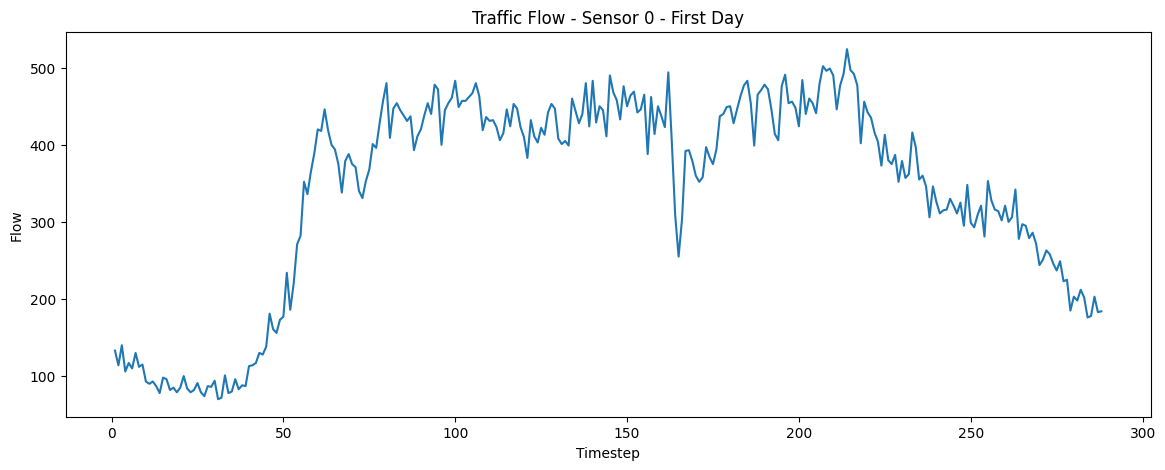

In [16]:
# Visualiser l'évolution du trafic (flow) pendant la première journée.
#
# flow représente le nombre de véhicules détectés.
# Un flow élevé signifie que beaucoup de véhicules passent,
# mais cela ne signifie pas forcément qu'il y a congestion.

plt.figure(figsize=(14, 5))

plt.plot(first_day["timestep"], first_day["flow"])

plt.title("Traffic Flow - Sensor 0 - First Day")
plt.xlabel("Timestep")
plt.ylabel("Flow")

plt.show()

### Interprétation

Le débit est faible au début de la journée puis augmente fortement à partir d'environ 40–60 timesteps.  
Il reste élevé pendant une grande partie de la journée, avec un maximum supérieur à 500.

On observe également une perturbation importante autour des timesteps 160–180.

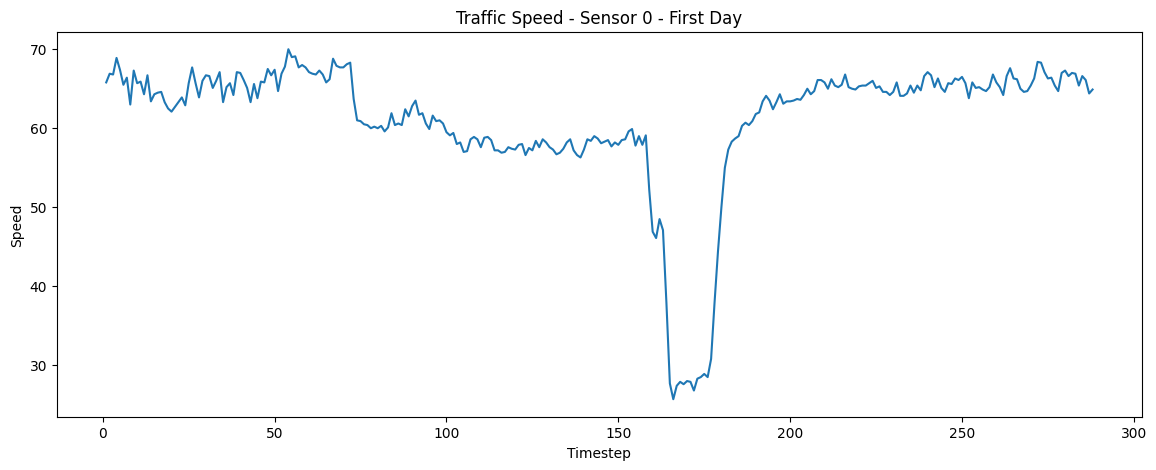

In [17]:
# Visualiser l'évolution de la vitesse des véhicules.
#
# Une baisse importante de la vitesse peut indiquer
# un ralentissement ou une situation de congestion.

plt.figure(figsize=(14, 5))

plt.plot(first_day["timestep"], first_day["speed"])

plt.title("Traffic Speed - Sensor 0 - First Day")
plt.xlabel("Timestep")
plt.ylabel("Speed")

plt.show()

### Interprétation

La vitesse reste globalement stable autour de 60–68 pendant la majorité de la journée.

Une forte chute apparaît autour des timesteps 160–180, où la vitesse descend sous 30.  
Cette baisse importante peut indiquer une période de congestion.

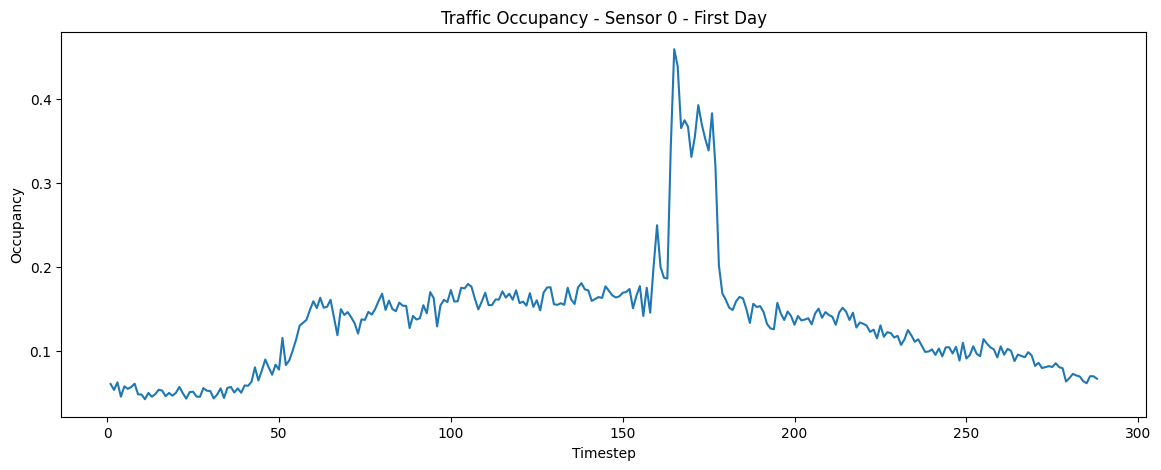

In [18]:
# Visualiser l'occupation du capteur.
#
# occupy représente la proportion de temps pendant laquelle
# le capteur est occupé par un véhicule.
#
# Une forte occupation combinée à une faible vitesse
# peut être un indicateur de congestion.

plt.figure(figsize=(14, 5))

plt.plot(first_day["timestep"], first_day["occupy"])

plt.title("Traffic Occupancy - Sensor 0 - First Day")
plt.xlabel("Timestep")
plt.ylabel("Occupancy")

plt.show()

### Interprétation

Le taux d'occupation augmente progressivement au cours de la journée.

Le changement le plus important apparaît autour des timesteps 160–180, où l'occupation augmente fortement jusqu'à environ 0.46.

Cette forte occupation, combinée à la baisse de vitesse observée au même moment, suggère une situation de congestion.

## Conclusion

Les trois visualisations montrent une période particulièrement importante autour des timesteps 160–180.

Pendant cette période :
- la vitesse diminue fortement ;
- l'occupation augmente fortement ;
- le débit présente une perturbation.

Ces observations indiquent une probable période de congestion et montrent que les variables `flow`, `speed` et `occupy` doivent être analysées ensemble pour détecter l'état du trafic.

## Analyse des relations entre variables

Nous utilisons toutes les observations du **capteur 0**, et non uniquement la premi?re journ?e. Chaque point des nuages correspond ? une observation. Cette analyse reste descriptive : une corr?lation ne prouve pas une relation de causalit?.


In [19]:
# Sélectionner uniquement les observations du capteur 0.
sensor_0 = df[df["location"] == 0].copy()

# Vérifier rapidement le résultat.
sensor_0.head()

,timestep,location,flow,occupy,speed
0,1,0,133.0,0.0603,65.8
170,2,0,114.0,0.0532,66.9
340,3,0,140.0,0.0622,66.8
510,4,0,106.0,0.0452,68.9
680,5,0,117.0,0.0574,67.4


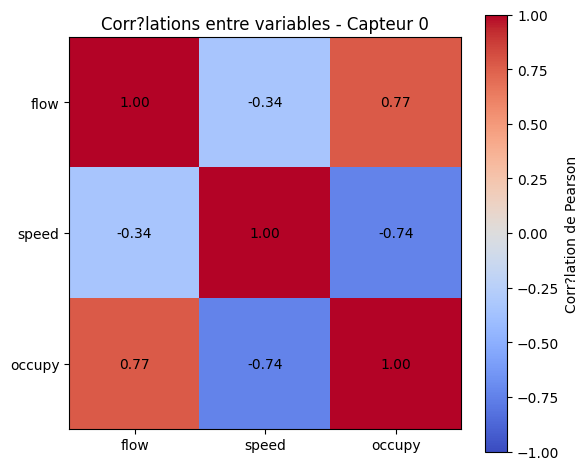

In [20]:
# Calculer les corr?lations de Pearson sur toutes les observations du capteur 0.
# Les coefficients vont de -1 (relation inverse) ? +1 (relation positive).
# Un coefficient proche de 0 indique une faible relation lin?aire.
variables = ["flow", "speed", "occupy"]
correlations = sensor_0[variables].corr()

# Afficher la matrice avec une ?chelle de couleurs fixe entre -1 et +1.
fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables)), labels=variables)
ax.set_yticks(range(len(variables)), labels=variables)

# Inscrire chaque coefficient dans sa case pour faciliter la lecture.
for i in range(len(variables)):
    for j in range(len(variables)):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}",
                ha="center", va="center", color="black")

fig.colorbar(heatmap, ax=ax, label="Corr?lation de Pearson")
ax.set_title("Corr?lations entre variables - Capteur 0")
plt.tight_layout()
plt.show()


### Interprétation

Le débit et l'occupation sont positivement corrélés (**0,77**), tandis que la vitesse et l'occupation sont négativement corrélées (**-0,74**). La relation linéaire entre débit et vitesse est moins marqu?e (**-0,34**). Les nuages de points permettent d'examiner les formes de ces relations.


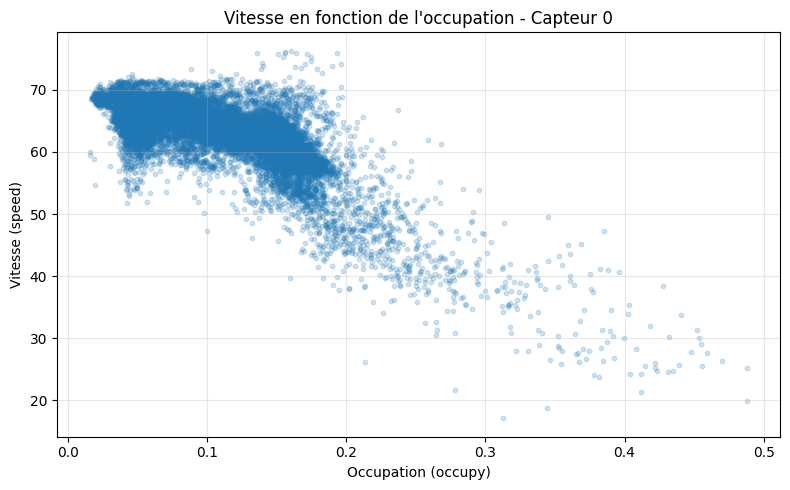

In [21]:
# Placer occupy sur l'axe horizontal et speed sur l'axe vertical.
# Chaque point repr?sente une mesure du capteur 0 sur l'ensemble de la p?riode.
plt.figure(figsize=(8, 5))

# Utiliser de petits points transparents pour rendre les superpositions lisibles.
plt.scatter(sensor_0["occupy"], sensor_0["speed"], s=10, alpha=0.2)
plt.xlabel("Occupation (occupy)")
plt.ylabel("Vitesse (speed)")
plt.title("Vitesse en fonction de l'occupation - Capteur 0")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interpr?tation

La vitesse est g?n?ralement ?lev?e lorsque l'occupation est faible, puis diminue lorsque l'occupation augmente. Une forte occupation associ?e ? une faible vitesse est compatible avec un ralentissement du trafic.


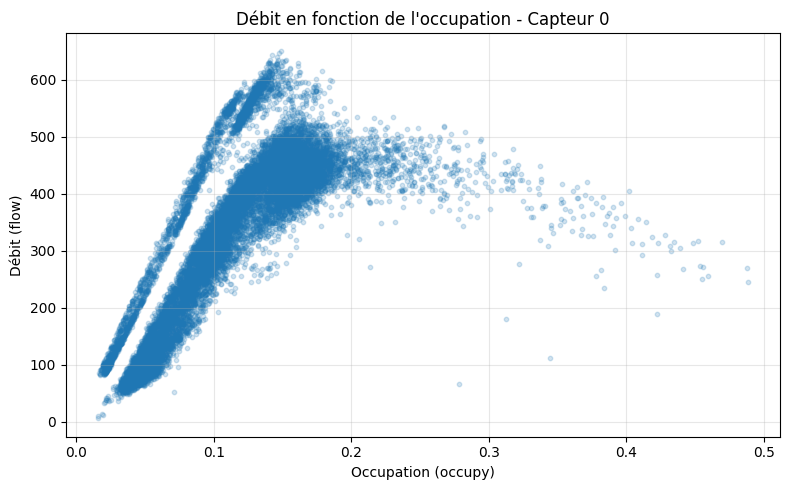

In [22]:
# Placer occupy sur l'axe horizontal et flow sur l'axe vertical.
# Chaque point repr?sente une mesure du capteur 0 sur l'ensemble de la p?riode.
plt.figure(figsize=(8, 5))

# Utiliser de petits points transparents pour rendre les superpositions lisibles.
plt.scatter(sensor_0["occupy"], sensor_0["flow"], s=10, alpha=0.2)
plt.xlabel("Occupation (occupy)")
plt.ylabel("Débit (flow)")
plt.title("Débit en fonction de l'occupation - Capteur 0")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation

Le d?bit augmente d'abord avec l'occupation. Aux occupations les plus ?lev?es, il tend ? diminuer : une route davantage occup?e ne laisse donc pas n?cessairement passer plus de v?hicules. Cette relation n'est pas strictement lin?aire.


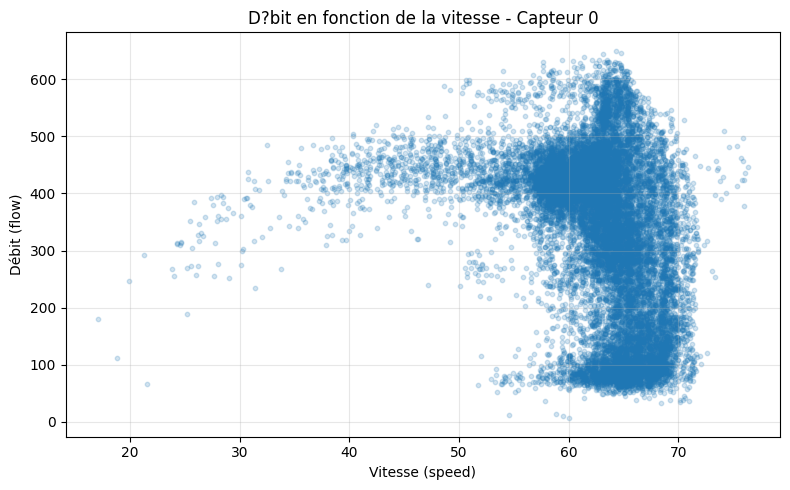

In [23]:
# Placer speed sur l'axe horizontal et flow sur l'axe vertical.
# Chaque point repr?sente une mesure du capteur 0 sur l'ensemble de la p?riode.
plt.figure(figsize=(8, 5))

# Utiliser de petits points transparents pour rendre les superpositions lisibles.
plt.scatter(sensor_0["speed"], sensor_0["flow"], s=10, alpha=0.2)
plt.xlabel("Vitesse (speed)")
plt.ylabel("Débit (flow)")
plt.title("D?bit en fonction de la vitesse - Capteur 0")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interprétation

Une vitesse élevée peut coexister avec des débits très diff?rents. Les débits les plus importants ne correspondent pas forcément aux vitesses maximales : la vitesse seule ne suffit pas à décrire l'état du trafic.


## Analyse globale des 170 capteurs

Nous comparons les statistiques de chaque capteur sur l'ensemble de la période disponible. Le terme **occupancy** correspond à la colonne **occupy** du dataset.

Cette analyse est exploratoire : une vitesse moyenne faible ou une occupation moyenne élevée ne suffit pas à conclure à une congestion. Les moyennes résument la période et peuvent masquer des variations temporelles importantes.


In [24]:
# Regrouper toutes les observations par capteur (location).
# Donner des noms explicites aux cinq statistiques demandées.
statistiques_capteurs = df.groupby("location").agg(
    flow_moyen=("flow", "mean"),
    speed_moyenne=("speed", "mean"),
    occupancy_moyenne=("occupy", "mean"),
    speed_minimale=("speed", "min"),
    occupancy_maximale=("occupy", "max"),
)

# Vérifier le nombre de capteurs et afficher leurs statistiques.
print("Nombre de capteurs :", len(statistiques_capteurs))
statistiques_capteurs


Nombre de capteurs : 170


,flow_moyen,speed_moyenne,occupancy_moyenne,speed_minimale,occupancy_maximale
location,,,,,
0,329.836246,62.605304,0.113511,17.1,0.4881
1,358.667843,63.535473,0.106088,12.7,0.4902
2,259.534106,61.591431,0.070230,24.4,0.5099
3,355.947917,61.787052,0.114739,6.4,0.5994
4,396.435988,56.183384,0.131653,11.2,0.5506
...,...,...,...,...,...
165,187.136593,67.411778,0.055318,24.2,0.2556
166,69.840838,63.287769,0.042644,10.3,0.3990
167,200.725582,55.599961,0.073936,4.1,0.5772


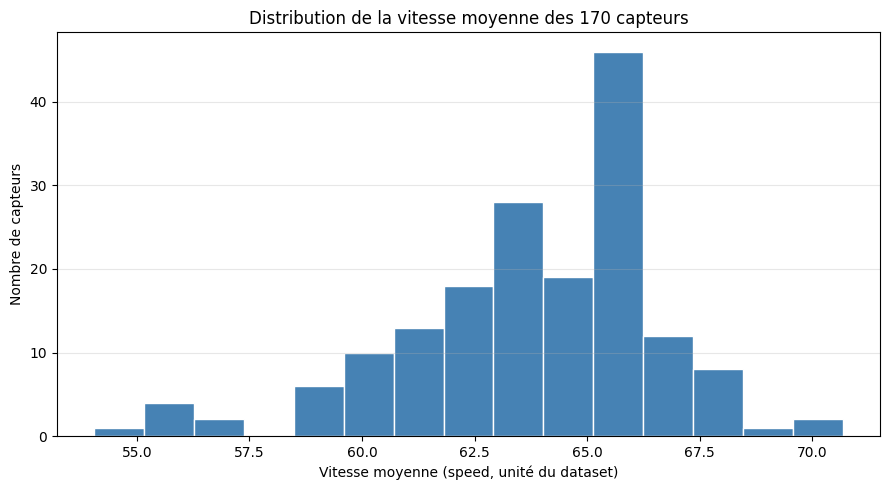

In [25]:
# Chaque valeur de l'histogramme correspond à la vitesse moyenne d'un capteur.
# Les classes servent uniquement à visualiser la distribution.
plt.figure(figsize=(9, 5))
plt.hist(statistiques_capteurs["speed_moyenne"], bins=15,
         color="steelblue", edgecolor="white")

# Le nombre de capteurs est représenté sur l'axe vertical.
plt.title("Distribution de la vitesse moyenne des 170 capteurs")
plt.xlabel("Vitesse moyenne (speed, unité du dataset)")
plt.ylabel("Nombre de capteurs")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


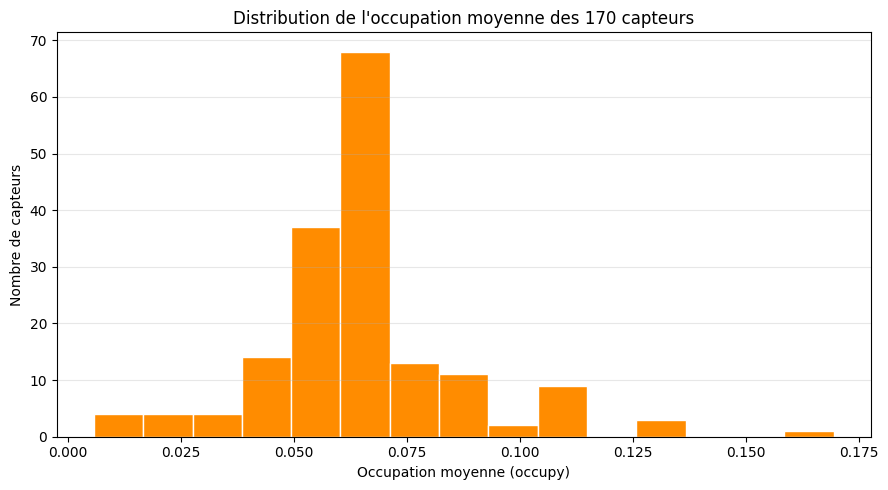

In [26]:
# Comparer la répartition des occupations moyennes entre capteurs.
# Conserver l'échelle de la colonne occupy, sans conversion en pourcentage.
plt.figure(figsize=(9, 5))
plt.hist(statistiques_capteurs["occupancy_moyenne"], bins=15,
         color="darkorange", edgecolor="white")

# Chaque capteur contribue une seule valeur à cet histogramme.
plt.title("Distribution de l'occupation moyenne des 170 capteurs")
plt.xlabel("Occupation moyenne (occupy)")
plt.ylabel("Nombre de capteurs")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Interprétation des distributions

Les vitesses moyennes varient d'environ **54,1 à 70,7**, avec la moitié des capteurs entre **62,2 et 65,6**. Les occupations moyennes sont davantage concentrées autour de **0,055 à 0,070**, avec quelques valeurs nettement plus élevées, jusqu'à **0,169**.

Ces différences indiquent des profils hétérogènes entre capteurs. Elles ne permettent pas, à elles seules, d'identifier des situations de congestion.


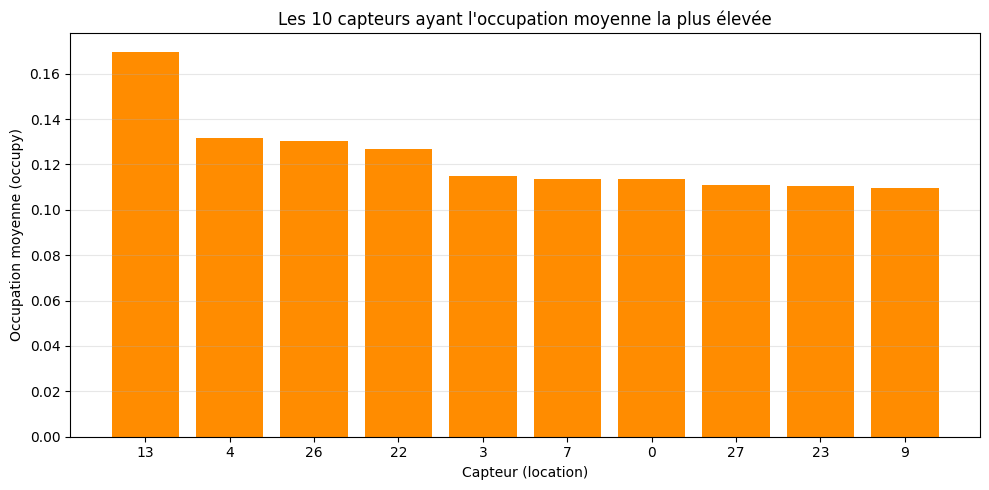

In [27]:
# Sélectionner les dix occupations moyennes les plus élevées.
# Ce classement sert à comparer des profils, sans définir de seuil de congestion.
top_occupancy = statistiques_capteurs.nlargest(10, "occupancy_moyenne")

# Convertir les identifiants en texte pour obtenir une barre par capteur.
plt.figure(figsize=(10, 5))
plt.bar(top_occupancy.index.astype(str), top_occupancy["occupancy_moyenne"],
        color="darkorange")
plt.title("Les 10 capteurs ayant l'occupation moyenne la plus élevée")
plt.xlabel("Capteur (location)")
plt.ylabel("Occupation moyenne (occupy)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


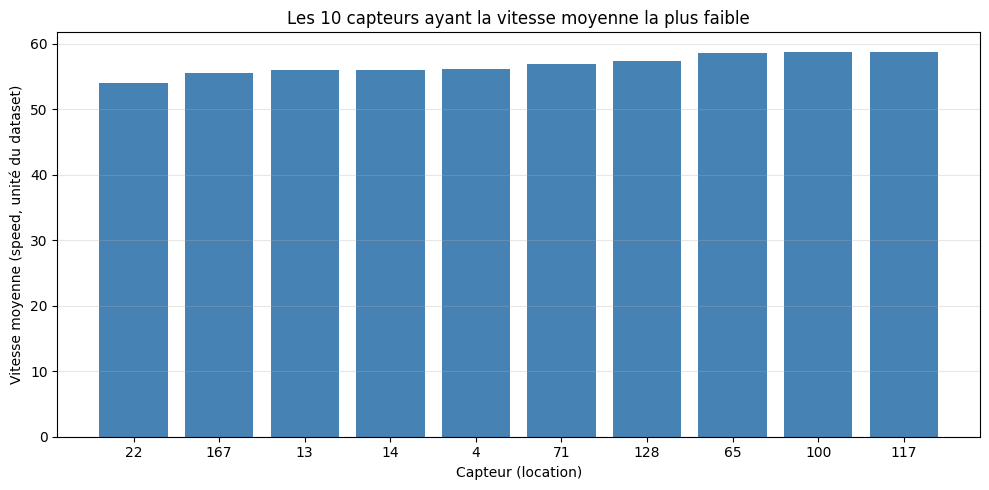

In [28]:
# Sélectionner les dix vitesses moyennes les plus faibles.
# Une vitesse moyenne faible ne constitue pas, seule, un diagnostic de congestion.
faibles_vitesses = statistiques_capteurs.nsmallest(10, "speed_moyenne")

# Afficher les capteurs dans l'ordre croissant de leur vitesse moyenne.
plt.figure(figsize=(10, 5))
plt.bar(faibles_vitesses.index.astype(str), faibles_vitesses["speed_moyenne"],
        color="steelblue")
plt.title("Les 10 capteurs ayant la vitesse moyenne la plus faible")
plt.xlabel("Capteur (location)")
plt.ylabel("Vitesse moyenne (speed, unité du dataset)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Interprétation des classements

Le capteur **13** présente l'occupation moyenne la plus élevée, tandis que le capteur **22** présente la vitesse moyenne la plus faible. Les capteurs **4, 13 et 22** apparaissent dans les deux classements, mais ceux-ci ne se recouvrent pas entièrement.

Ces classements permettent de choisir des capteurs à examiner plus en détail. Ils ne constituent pas une liste de capteurs congestionnés : il faut également étudier le débit et l'évolution temporelle des mesures.


### Conclusion

Certains capteurs présentent des profils moyens différents en matière de débit, de vitesse et d'occupation. Pour caractériser la congestion, il faudra ensuite analyser conjointement les relations entre **speed**, **flow** et **occupancy**, ainsi que leur évolution dans le temps pour les différents capteurs. Cette étape reste une analyse exploratoire, sans variable de congestion ni modèle de machine learning.


## Caractérisation de la congestion

Nous explorons les mesures des **170 capteurs sur toute la période** afin d'étudier les rôles de **flow**, **speed** et **occupy**. Les statistiques utilisent toutes les observations ; seul le nuage de points sera échantillonné pour faciliter sa lecture.

Les quantiles servent de repères descriptifs pour sélectionner des exemples contrastés, **pas de seuils de congestion**. Les différences entre capteurs doivent également être prises en compte avant toute définition opérationnelle.


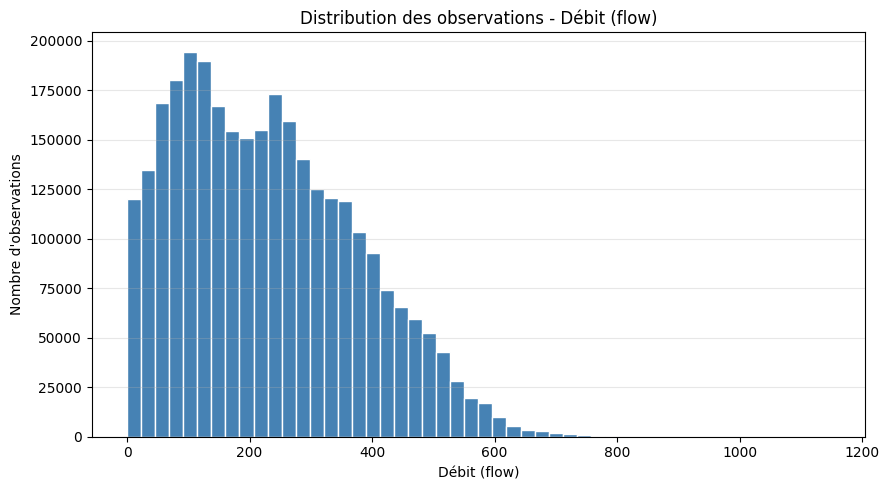

In [29]:
# Visualiser la distribution de flow sur toutes les observations.
# Les classes de l'histogramme servent à décrire les données, pas à définir la congestion.
plt.figure(figsize=(9, 5))
plt.hist(df["flow"], bins=50, color="steelblue", edgecolor="white")
plt.title("Distribution des observations - Débit (flow)")
plt.xlabel("Débit (flow)")
plt.ylabel("Nombre d'observations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


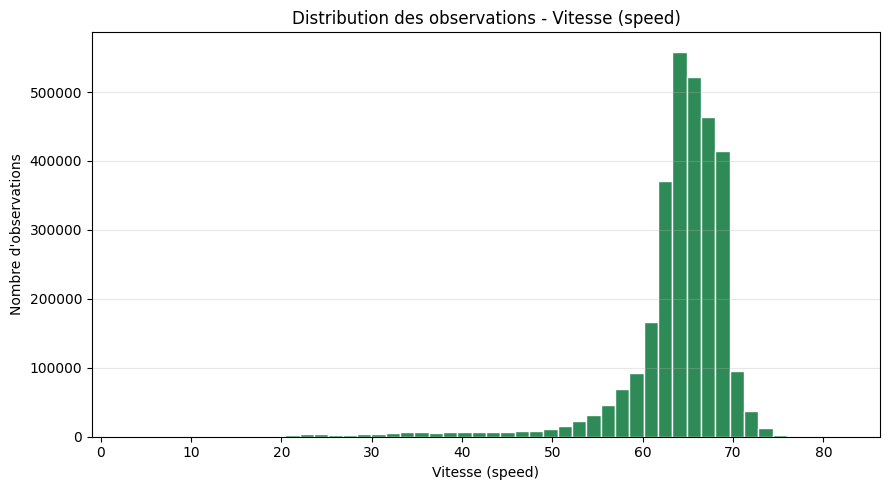

In [30]:
# Visualiser la distribution de speed sur toutes les observations.
# Les classes de l'histogramme servent à décrire les données, pas à définir la congestion.
plt.figure(figsize=(9, 5))
plt.hist(df["speed"], bins=50, color="seagreen", edgecolor="white")
plt.title("Distribution des observations - Vitesse (speed)")
plt.xlabel("Vitesse (speed)")
plt.ylabel("Nombre d'observations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


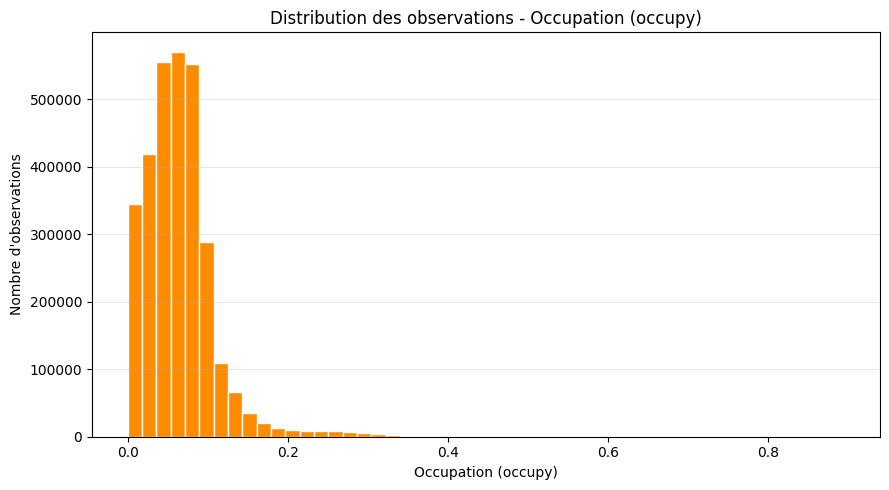

In [31]:
# Visualiser la distribution de occupy sur toutes les observations.
# Les classes de l'histogramme servent à décrire les données, pas à définir la congestion.
plt.figure(figsize=(9, 5))
plt.hist(df["occupy"], bins=50, color="darkorange", edgecolor="white")
plt.title("Distribution des observations - Occupation (occupy)")
plt.xlabel("Occupation (occupy)")
plt.ylabel("Nombre d'observations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Interprétation des distributions

Les vitesses se concentrent autour des valeurs élevées, avec une queue vers les faibles vitesses. L'occupation présente une queue vers les valeurs élevées, tandis que le débit couvre une large plage. Les quantiles suivants précisent la répartition sans imposer de catégories de trafic.


In [32]:
# Calculer les quantiles demandés sur l'ensemble des observations.
# Par exemple, le quantile 5 % est la valeur sous laquelle se trouvent environ 5 % des mesures.
niveaux_quantiles = [0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
quantiles_trafic = df[["flow", "speed", "occupy"]].quantile(niveaux_quantiles)

# Afficher les pourcentages sans modifier l'index numérique utilisé ensuite.
table_quantiles = quantiles_trafic.copy()
table_quantiles.index = ["5 %", "25 %", "50 %", "75 %", "90 %", "95 %", "99 %"]
table_quantiles.index.name = "Quantile"
table_quantiles


,flow,speed,occupy
Quantile,,,
5 %,29.0,53.7,0.0113
25 %,110.0,62.6,0.0357
50 %,215.0,64.9,0.0601
75 %,334.0,67.4,0.0839
90 %,438.0,68.7,0.1078
95 %,497.0,69.6,0.1357
99 %,590.0,72.0,0.2575


### Interprétation des quantiles

La vitesse médiane vaut **64,9**, contre **53,7** au quantile 5 %. L'occupation médiane vaut **0,0601**, contre **0,1357** au quantile 95 % et **0,2575** au quantile 99 %. Le débit atteint **497** au quantile 95 %.

Nous utiliserons les quantiles 5 % et 95 % pour explorer les faibles vitesses et fortes occupations. Pour le contraste « débit élevé et vitesse élevée », nous retiendrons les quantiles 95 % du débit et 75 % de la vitesse. Ces choix de sélection sont explicites mais restent exploratoires : ils ne constituent pas une définition validée de la congestion.


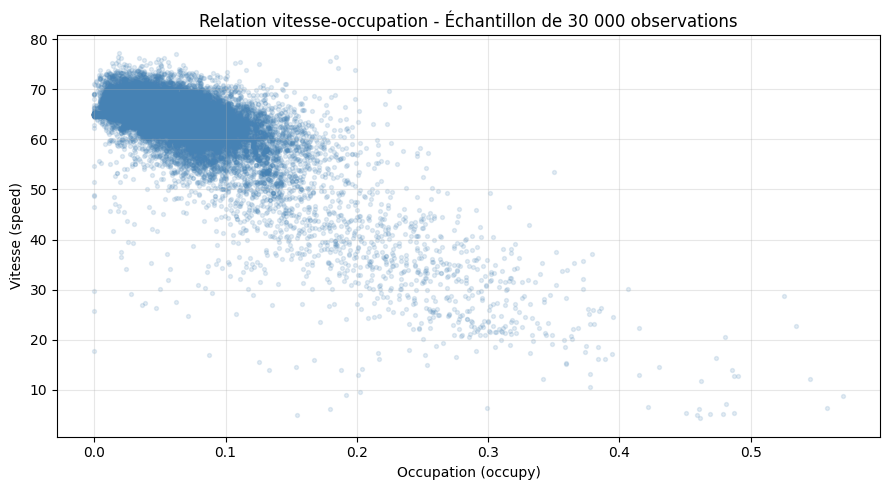

In [33]:
# Prélever un échantillon reproductible pour limiter la superposition des points.
echantillon_relations = df.sample(n=min(30000, len(df)), random_state=42)

# Examiner conjointement la vitesse et l'occupation sans tracer de seuil.
plt.figure(figsize=(9, 5))
plt.scatter(echantillon_relations["occupy"], echantillon_relations["speed"],
            s=8, alpha=0.15, color="steelblue")
plt.title("Relation vitesse-occupation - Échantillon de 30 000 observations")
plt.xlabel("Occupation (occupy)")
plt.ylabel("Vitesse (speed)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [34]:
# Sélectionner les queues de distribution pour comparer des observations.
# Ces masques servent uniquement à l'exploration et ne sont pas des étiquettes de congestion.
vitesse_basse = df["speed"] <= quantiles_trafic.loc[0.05, "speed"]
occupation_haute = df["occupy"] >= quantiles_trafic.loc[0.95, "occupy"]

# Comparer l'occupation des observations à faible vitesse à celle des autres observations.
comparaison_occupation = pd.DataFrame({
    "Nombre d'observations": [
        vitesse_basse.sum(), (~vitesse_basse).sum()
    ],
    "Occupation moyenne": [
        df.loc[vitesse_basse, "occupy"].mean(),
        df.loc[~vitesse_basse, "occupy"].mean()
    ],
    "Occupation médiane": [
        df.loc[vitesse_basse, "occupy"].median(),
        df.loc[~vitesse_basse, "occupy"].median()
    ]
}, index=["Vitesse <= quantile 5 %", "Autres observations"])

# Quantifier le recouvrement des deux sélections sur les données complètes.
part_occupation_haute = occupation_haute[vitesse_basse].mean() * 100
print(f"Occupation >= quantile 95 % parmi les faibles vitesses : {part_occupation_haute:.1f} %")
print("Corrélation speed-occupy :", round(df["speed"].corr(df["occupy"]), 3))
comparaison_occupation


Occupation >= quantile 95 % parmi les faibles vitesses : 65.9 %
Corrélation speed-occupy : -0.752


,Nombre d'observations,Occupation moyenne,Occupation médiane
Vitesse <= quantile 5 %,153521,0.182212,0.1646
Autres observations,2881999,0.058831,0.0578


### Interprétation de la relation vitesse-occupation

La relation globale est négative : la corrélation entre vitesse et occupation est d'environ **-0,752**. L'occupation médiane est de **0,1646** dans les observations à faible vitesse, contre **0,0578** dans les autres. Environ **65,9 %** des observations à faible vitesse appartiennent aussi à la sélection de forte occupation.

L'association est donc marquée, mais pas systématique. Ces résultats regroupent des capteurs différents et ne prouvent ni une causalité ni la présence de congestion pour chaque observation sélectionnée.


In [35]:
# Afficher des observations combinant faible vitesse et forte occupation.
# Trier pour montrer d'abord les vitesses les plus faibles, puis les occupations les plus élevées.
exemples_vitesse_basse = (
    df.loc[vitesse_basse & occupation_haute,
           ["timestep", "location", "flow", "speed", "occupy"]]
    .sort_values(["speed", "occupy"], ascending=[True, False])
    .head(10)
)

# Conserver timestep et location pour pouvoir retrouver ces observations dans leur contexte.
exemples_vitesse_basse


,timestep,location,flow,speed,occupy
1163334,6844,24,15.0,3.0,0.8854
1163844,6847,24,24.0,3.0,0.8338
1163073,6842,103,18.0,3.0,0.8247
1162994,6842,24,16.0,3.0,0.8241
1161713,6834,103,16.0,3.0,0.8158
1161634,6834,24,20.0,3.0,0.7995
1164093,6848,103,21.0,3.0,0.7963
1163243,6843,103,16.0,3.0,0.7931
1162824,6841,24,22.0,3.0,0.7863
1163923,6847,103,24.0,3.0,0.7689


### Exemples de faible vitesse et forte occupation

Parmi ces observations extrêmes, la vitesse vaut **3,0** avec une occupation pouvant dépasser **0,8** et un débit parfois très faible. Cette combinaison est compatible avec un trafic fortement ralenti. Il faut toutefois examiner les mesures voisines et leur qualité avant de conclure ; ces exemples sélectionnés ne représentent pas l'ensemble du dataset.


In [ ]:
# Chercher un débit dans les 5 % supérieurs accompagné d'une vitesse dans le quart supérieur.
# Ces repères proviennent des quantiles observés et servent à construire un contre-exemple.
debit_eleve = df["flow"] >= quantiles_trafic.loc[0.95, "flow"]
vitesse_elevee = df["speed"] >= quantiles_trafic.loc[0.75, "speed"]

# Afficher les plus forts débits de cette sélection avec les deux autres variables.
exemples_debit_eleve = (
    df.loc[debit_eleve & vitesse_elevee,
           ["timestep", "location", "flow", "speed", "occupy"]]
    .sort_values("flow", ascending=False)
    .head(10)
)
exemples_debit_eleve


,timestep,location,flow,speed,occupy
1073724,6317,4,1077.0,69.0,0.2731
1315974,7742,4,1052.0,72.5,0.2449
1316144,7743,4,1040.0,73.4,0.2339
1316484,7745,4,1033.0,71.2,0.2284
1314954,7736,4,998.0,69.8,0.2211
1072534,6310,4,952.0,68.1,0.2529
972744,5723,4,945.0,72.9,0.1995
1315804,7741,4,942.0,72.8,0.2086
972574,5722,4,936.0,69.4,0.2169
972404,5721,4,932.0,69.3,0.2197


: 

### Exemples de débit élevé avec vitesse élevée

Au capteur **4**, le timestep **6317** présente un débit de **1077** et une vitesse de **69,0**. Le timestep **7743** présente un débit de **1040** avec une vitesse de **73,4**. Un débit élevé peut donc accompagner une circulation rapide : **flow seul ne suffit pas à identifier la congestion**.


### Conclusion

La combinaison d'une **baisse de speed** et d'une **hausse de occupy** paraît la plus pertinente pour explorer les situations de congestion. **Flow** apporte un contexte complémentaire : un débit élevé peut correspondre à une circulation rapide, tandis qu'un ralentissement important peut s'accompagner d'un débit faible.

Une future définition devra tenir compte du profil habituel de chaque capteur, du moment de la journée et de la durée des épisodes. Les quantiles présentés sont des repères descriptifs, sans seuil de congestion validé, sans création de variable congestion et sans modèle de machine learning.
